# 5. Confirmed and not confirmed speakers

Looking at the pages from notebook 4 one by one. CPU is enough.
Inputs: task data, `magi_output.json` (notebook 1), `char_embeddings.json` (notebook 4).

In [1]:
import os
import re
import sys
import json
import math
import random
import numpy as np
from PIL import Image
from collections import Counter
from functools import lru_cache
import cv2
import matplotlib.pyplot as plt
from PIL import ImageDraw, ImageFont

In [3]:
def find(name):
    for top in ["/kaggle/working", "/kaggle/input", ".."]:
        for root, dirs, files in os.walk(top, followlinks=True):
            if name in files:
                return root + "/" + name
    return None

DATA = os.path.dirname(find("sequences.json"))
MAGI = find("magi_output.json")
print(DATA)
print(MAGI)
OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "../data"

sys.path.insert(0, DATA)
import score
from score import load_jsonl, evaluate, tokens, align_tokens

magi = json.load(open(MAGI))
gold = load_jsonl(DATA + "/development/labels.jsonl", reference=True)
images = {}
for s in json.load(open(DATA + "/sequences.json")):
    images[s["sequence_id"]] = [DATA + "/" + p for p in s["images"]]
dev = sorted(gold.keys())
test = [s for s in magi if magi[s]["split"] == "test"]

emb_file = find("char_embeddings.json")
if emb_file is None:
    emb_file = find("char_embeddings (1).json")     # the name kaggle gave my upload
emb = json.load(open(emb_file))

/kaggle/input/datasets/arpitparashar06/manga-task/manga-task-upload/manga-task/dataset
/kaggle/input/datasets/arpitparashar06/manga-task/magi_output.json


In [4]:
# speed up: the scorer lines up our words with the gold words every time.
# while tuning only the speaker names change, not the text, so remember the line-up.
original_align = score.align_tokens
saved = {}

def remembered_align(g, p):
    key = (tuple(t[0] for t in g), tuple(t[0] for t in p))
    if key not in saved:
        saved[key] = [(a[1], b[1], w) for a, b, w in original_align([(g[i][0], i) for i in range(len(g))],
                                                                    [(p[j][0], j) for j in range(len(p))])]
    return [(g[i], p[j], w) for i, j, w in saved[key]]

score.align_tokens = remembered_align
score.distance = lru_cache(maxsize=None)(score.distance)     # same for the page text comparison

In [5]:
def read_sequence(sid, emb=None):
    # lines = every story line in reading order: [page, text, group]
    # group = (page, magi group) or None if magi linked it to nobody
    lines = []
    groups = {}
    for p in range(3):
        r = magi[sid]["pages"][p]
        link = {a: b for a, b in r["links"]}
        for i in range(len(r["ocr"])):
            if r["keep"][i] == True and r["ocr"][i].strip() != "":
                group = None
                c = link.get(i, -1)
                if 0 <= c < len(r["clusters"]):
                    group = (p, r["clusters"][c])
                    if group not in groups:
                        groups[group] = {"lines": []}
                    groups[group]["lines"].append(len(lines))
                lines.append([p, r["ocr"][i].strip(), group])

        # every group gets one fingerprint: the average of its boxes
        key = sid + "|" + str(p)
        if emb is None or key not in emb or len(emb[key]) == 0:
            continue
        E = np.array(emb[key], dtype=np.float32)
        E = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-8)
        for (gp, g) in groups:
            if gp != p:
                continue
            rows = [c for c in range(min(len(r["clusters"]), len(E))) if r["clusters"][c] == g]
            if len(rows) == 0:
                continue
            v = E[rows].mean(0)
            groups[(p, g)]["vec"] = v / (np.linalg.norm(v) + 1e-8)
    return lines, groups

In [6]:
def draw(sid, p):
    # blue = kept text with its number, red = character box with its magi group, green = magi's link
    r = magi[sid]["pages"][p]
    pic = Image.open(images[sid][p]).convert("RGB")
    d = ImageDraw.Draw(pic)
    try:
        font = ImageFont.load_default(size=26)
    except TypeError:
        font = ImageFont.load_default()
    for c in range(len(r["char_boxes"])):
        b = r["char_boxes"][c]
        d.rectangle(b, outline=(220, 0, 0), width=4)
        d.text((b[0] + 4, b[1] + 4), "group " + str(r["clusters"][c]), fill=(220, 0, 0), font=font)
    link = {a: b for a, b in r["links"]}
    for i in range(len(r["text_boxes"])):
        if not r["keep"][i]:
            continue
        b = r["text_boxes"][i]
        d.rectangle(b, outline=(0, 90, 255), width=4)
        d.text((b[0] + 4, b[1] + 4), str(i), fill=(0, 90, 255), font=font)
        if i in link and link[i] < len(r["char_boxes"]):
            cb = r["char_boxes"][link[i]]
            d.line([((b[0] + b[2]) / 2, (b[1] + b[3]) / 2), ((cb[0] + cb[2]) / 2, (cb[1] + cb[3]) / 2)], fill=(0, 170, 0), width=4)
    plt.figure(figsize=(12, 18))
    plt.imshow(pic)
    plt.axis("off")
    plt.show()

def compare(sid, p):
    lines, groups = read_sequence(sid)
    print("MAGI")
    for page, text, g in lines:
        if page == p:
            print("  %-10s %s" % ("-" if g is None else "group" + str(g[1]), text[:70]))
    print("GOLD")
    for x in gold[sid][p]:
        print("  %-10s %s" % (x["speaker"], x["text"][:70]))

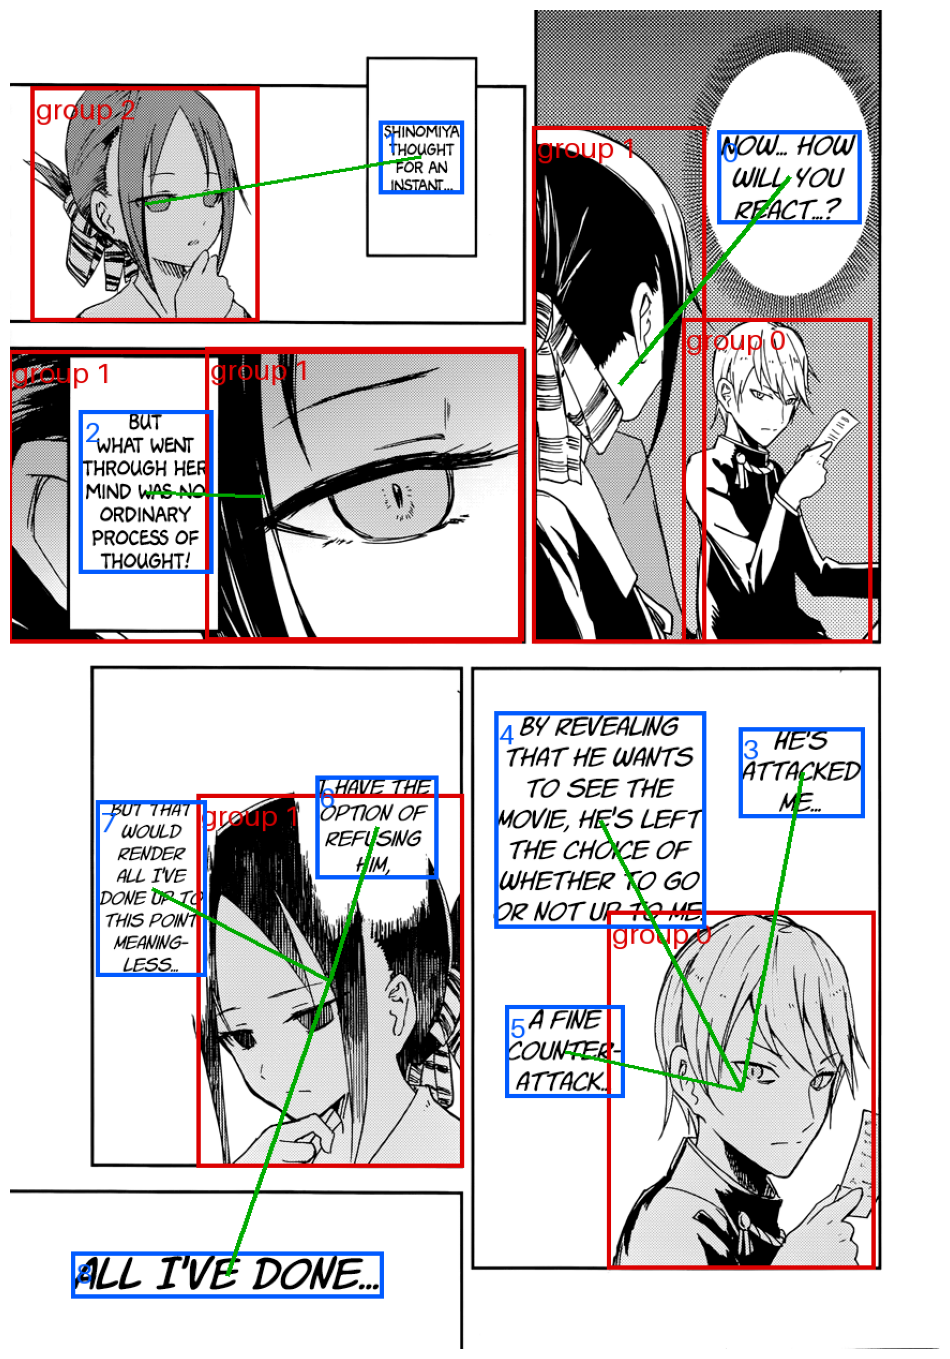

MAGI
  group1     Now... how will you react...?
  group2     Shinomiya thought for an instant...
  group1     But what went through her mind was no ordinary process of thought!
  group0     He's attacked me...
  group0     By revealing that he wants to see the movie, he's left the choice of w
  group0     A fine counter- attack...
  group1     I have the option of refusing him,
  group1     But that would render all I've done up to this point meaning- less...
  group1     All I've done...
GOLD
  character1 NOW... HOW WILL YOU REACT...?
  NARRATION  SHINOMIYA THOUGHT FOR AN INSTANT...
  NARRATION  BUT WHAT WENT THROUGH HER MIND WAS NO ORDINARY PROCESS OF THOUGHT!
  character2 HE'S ATTACKED ME...
  character2 BY REVEALING THAT HE WANTS TO SEE THE MOVIE, HE'S LEFT THE CHOICE OF W
  character2 A FINE COUNTER-ATTACK...
  character2 I HAVE THE OPTION OF REFUSING HIM,
  character2 BUT THAT WOULD RENDER ALL I'VE DONE UP TO THIS POINT MEANINGLESS...
  character2 ALL I'VE DONE...


In [7]:
# a kaguya-sama page
draw("seq_b251c8e1ba8b91f8", 0)
compare("seq_b251c8e1ba8b91f8", 0)

what i see: lines 3-5 ("He's attacked me...") are kaguya's thoughts floating in the air,
but magi gives them to the boy drawn next to them.

my rule: a speaker is **confirmed** when the text is inside a speech bubble, thought cloud or box.
text floating in the air is **not confirmed** -> it belongs to the last confirmed speaker.

## is the text inside a bubble / box or in the air? (opencv, no training)

- it has a speech-bubble tail (magi finds those) -> inside
- white letters on a solid black box -> inside
- dark busy background behind the letters -> drawn on the art -> air
- the white paper around the text is a small closed region -> inside
- or: rays sent out in 24 directions hit an outline all around, close to the text -> inside

In [8]:
def outline_rays(gray, box):
    H, W = gray.shape
    x1, y1, x2, y2 = [float(v) for v in box]
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    reach = max(60.0, 0.8 * max(x2 - x1, y2 - y1))
    dists = []
    for k in range(24):
        a = 2 * math.pi * k / 24
        dx, dy = math.cos(a), math.sin(a)
        to_x = (x2 - x1) / 2 / abs(dx) if abs(dx) > 1e-6 else 1e9
        to_y = (y2 - y1) / 2 / abs(dy) if abs(dy) > 1e-6 else 1e9
        start = min(to_x, to_y) + 2          # just outside the text box
        d = 0
        while d <= reach:
            x = int(round(cx + dx * (start + d)))
            y = int(round(cy + dy * (start + d)))
            if x < 0 or y < 0 or x >= W or y >= H:
                break
            if gray[y, x] < 140:
                dists.append(d)
                break
            d += 1
    hit_share = len(dists) / 24
    padding = float(np.median(dists)) if len(dists) > 0 else -1
    return hit_share, padding

def inside_bubble_or_box(gray, text_boxes):
    H, W = gray.shape
    dark = (gray <= 180).astype(np.uint8)
    dark = cv2.dilate(dark, np.ones((7, 7), np.uint8))     # close small gaps (dotted thought clouds)
    for b in text_boxes:                                     # rub out the letters
        x1, y1, x2, y2 = [int(round(v)) for v in b]
        dark[max(0, y1):y2 + 1, max(0, x1):x2 + 1] = 0
    n, labels, stats, _ = cv2.connectedComponentsWithStats(1 - dark, connectivity=4)
    result = []
    for b in text_boxes:
        x1, y1, x2, y2 = [int(round(v)) for v in b]
        letters = gray[max(0, y1):y2 + 1, max(0, x1):x2 + 1]
        white = (letters > 200).mean()
        black = (letters < 60).mean()
        grey = 1 - white - black
        label = labels[min(H - 1, (y1 + y2) // 2), min(W - 1, (x1 + x2) // 2)]
        sx, sy, sw, sh, area = stats[label]
        touches_edge = sx <= 1 or sy <= 1 or sx + sw >= W - 1 or sy + sh >= H - 1
        closed = (not touches_edge) and area <= 0.08 * H * W
        hit_share, padding = outline_rays(gray, b)
        if black > 0.5 and grey < 0.15:
            inside = True
        elif white < 0.6:
            inside = False
        elif closed:
            inside = True
        elif hit_share >= 0.7 and (4 <= padding <= 35 or hit_share >= 0.95):
            inside = True
        else:
            inside = False
        result.append(inside)
    return result

def line_info(sid):
    info = []
    for p in range(3):
        r = magi[sid]["pages"][p]
        has_tail = [a for a, b in r["tail_links"]]
        gray = np.array(Image.open(images[sid][p]).convert("L"))
        inside = inside_bubble_or_box(gray, r["text_boxes"])
        for i in range(len(r["ocr"])):
            if r["keep"][i] == True and r["ocr"][i].strip() != "":
                tail = i in has_tail
                info.append({"tail": tail, "inside": inside[i], "confirmed": tail or inside[i]})
    return info

In [9]:
info = {}
for sid in magi:
    info[sid] = line_info(sid)
json.dump(info, open(OUT + "/confirmed.json", "w"))

# check: a text with a tail is surely in a bubble
with_tail = [x for sid in dev for x in info[sid] if x["tail"]]
print("texts with a tail called inside: %.0f%%" % (100 * np.mean([x["inside"] for x in with_tail])))
print("texts in the air:", sum(not x["confirmed"] for sid in dev for x in info[sid]), "of", sum(len(info[sid]) for sid in dev))

lines, groups = read_sequence("seq_b251c8e1ba8b91f8")
for n in range(len(lines)):
    if lines[n][0] == 0:
        print("confirmed" if info["seq_b251c8e1ba8b91f8"][n]["confirmed"] else "AIR      ", lines[n][1][:60])

texts with a tail called inside: 96%
texts in the air: 85 of 1851
confirmed Now... how will you react...?
confirmed Shinomiya thought for an instant...
confirmed But what went through her mind was no ordinary process of th
AIR       He's attacked me...
AIR       By revealing that he wants to see the movie, he's left the c
AIR       A fine counter- attack...
confirmed I have the option of refusing him,
AIR       But that would render all I've done up to this point meaning
AIR       All I've done...


## the rule

In [10]:
def confirmed_speaker_rule(lines, inf):
    last = None
    for n in range(len(lines)):
        if not inf[n]["confirmed"] and last is not None:
            lines[n][2] = last                 # in the air -> last confirmed speaker
        if inf[n]["confirmed"] and lines[n][2] is not None:
            last = lines[n][2]
    return lines

In [11]:
# the kaguya page again: magi's group before and after the rule
lines, groups = read_sequence("seq_b251c8e1ba8b91f8")
fixed = confirmed_speaker_rule([list(x) for x in lines], info["seq_b251c8e1ba8b91f8"])
for a, b in zip(lines, fixed):
    if a[0] == 0:
        print("%-8s -> %-8s %s" % ("-" if a[2] is None else "group" + str(a[2][1]), "-" if b[2] is None else "group" + str(b[2][1]), a[1][:55]))

group1   -> group1   Now... how will you react...?
group2   -> group2   Shinomiya thought for an instant...
group1   -> group1   But what went through her mind was no ordinary process 
group0   -> group1   He's attacked me...
group0   -> group1   By revealing that he wants to see the movie, he's left 
group0   -> group1   A fine counter- attack...
group1   -> group1   I have the option of refusing him,
group1   -> group1   But that would render all I've done up to this point me
group1   -> group1   All I've done...


## score: fingerprints from notebook 4, with and without the rule

In [12]:
def merge_groups(groups, T):
    # start with every magi group alone, keep joining the two most alike while they are above T
    keys = sorted([k for k in groups if "vec" in groups[k]])
    clusters = [[k] for k in keys]
    while True:
        best = None
        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                s = float(np.mean([groups[a]["vec"] @ groups[b]["vec"] for a in clusters[i] for b in clusters[j]]))
                if s > T and (best is None or s > best[0]):
                    best = (s, i, j)
        if best is None:
            break
        clusters[best[1]] = clusters[best[1]] + clusters[best[2]]
        del clusters[best[2]]
    person = {}
    for n in range(len(clusters)):
        for k in clusters[n]:
            person[k] = "c" + str(n)
    return person

def finish(lines, person, CAP):
    rows = []
    for page, text, g in lines:
        spk = None
        if g is not None:
            spk = person[g] if g in person else "p" + str(g[0]) + "_g" + str(g[1])
        rows.append([page, text, spk])

    # magi linked it to nobody -> previous speaker (or the next one at the start)
    for i in range(len(rows)):
        if rows[i][2] is None:
            spk = None
            for x in range(i - 1, -1, -1):
                if rows[x][2] is not None:
                    spk = rows[x][2]
                    break
            if spk is None:
                for x in range(i + 1, len(rows)):
                    if rows[x][2] is not None:
                        spk = rows[x][2]
                        break
            rows[i][2] = spk if spk is not None else "NARRATION"

    # keep the CAP most talkative, the rest -> previous kept speaker
    count = Counter(r[2] for r in rows if r[2] != "NARRATION")
    keep = [name for name, n in count.most_common(CAP)]
    last = None
    for r in rows:
        if r[2] != "NARRATION" and r[2] not in keep:
            r[2] = last if last is not None else keep[0]
        if r[2] != "NARRATION":
            last = r[2]

    names = {}
    pages = [[], [], []]
    for page, text, spk in rows:
        if spk != "NARRATION":
            if spk not in names:
                names[spk] = "character" + str(len(names) + 1)
            spk = names[spk]
        pages[page].append({"speaker": spk, "text": text})
    return pages

def predict(sid, T, CAP, rule):
    lines, groups = read_sequence(sid, emb)
    if rule:
        lines = confirmed_speaker_rule(lines, info[sid])
    return finish(lines, merge_groups(groups, T), CAP)

In [13]:
def avg(scores, ids):
    # same as the scorer: mean over the sequences that have a score
    vals = [scores[s] for s in ids if scores[s] is not None]
    return sum(vals) / len(vals)

def score_each(predict_fn):
    # balanced_joint_f1 of every dev sequence on its own
    return {sid: evaluate({sid: gold[sid]}, {sid: predict_fn(sid)})["macro"]["balanced_joint_f1"] for sid in dev}

def cross_validate(grid, seed):
    # pick the setting on 4/5 of the sequences, score it on the other 1/5
    ids = list(dev)
    random.Random(seed).shuffle(ids)
    total = 0
    for k in range(5):
        held = ids[k::5]
        fit = [s for s in ids if s not in held]
        best = max(grid, key=lambda st: avg(grid[st], fit))
        total += avg(grid[best], held) / 5
    return total

grid = {False: {}, True: {}}
for rule in [False, True]:
    for T in [0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85]:
        for CAP in [99, 4, 3]:
            grid[rule][(T, CAP)] = score_each(lambda sid: predict(sid, T, CAP, rule))

cv_without = np.array([cross_validate(grid[False], seed) for seed in range(200)])
cv_with = np.array([cross_validate(grid[True], seed) for seed in range(200)])
print("5-fold CV, mean of 200 splits")
print("  fingerprints:             %.3f" % cv_without.mean())
print("  fingerprints + my rule:   %.3f" % cv_with.mean())
print("  gain: %+.3f, better in %.0f%% of the splits" % ((cv_with - cv_without).mean(), 100 * np.mean(cv_with > cv_without)))
best = max(grid[True], key=lambda k: avg(grid[True][k], dev))
print("best setting on all 80 with the rule:", best, "%.3f" % avg(grid[True][best], dev))

5-fold CV, mean of 200 splits
  fingerprints:             0.468
  fingerprints + my rule:   0.472
  gain: +0.004, better in 80% of the splits
best setting on all 80 with the rule: (0.75, 3) 0.485


it helps, but only a little (+0.004): only ~5% of the lines float in the air.

another thing i saw on the pages: magi has no NARRATION at all, the narration boxes get linked to a face -> notebook 6

In [14]:
T, CAP = best
f = open(OUT + "/confirmed_dev.jsonl", "w")
for sid in dev:
    f.write(json.dumps({"sequence_id": sid, "pages": predict(sid, T, CAP, True)}) + "\n")
f.close()

!python "{DATA}/score.py" --references "{DATA}/development/labels.jsonl" --predictions "{OUT}/confirmed_dev.jsonl" --output "{OUT}/confirmed_dev_scores.json"

{
  "text_order_score": 0.9293819876464963,
  "balanced_joint_f1": 0.4850171280882194,
  "speaker_accuracy_on_matched": 0.6840693524556994,
  "joint_f1": 0.6468195298910182,
  "matched_token_coverage": 0.9627321856604695
}
